# 27 — Test A dry run: the pre-registered Michigan model on 2024 data

**This is not Test A.** Test A (`report/preregistration_2026_general.md`) compares El-Sayed with Benson on the November 2026 ballot and cannot run until Michigan certifies. This notebook runs the *identical* specification on the 2024 ballot, with Slotkin in El-Sayed's place and Harris in Benson's, to check the pipeline and show how precisely the model measures a swing gradient between two mainstream Democrats on the same ballot. Nothing here changes the pre-registered plan.

**Specification (copied from the plan).** Unit: Michigan municipality (`src/data_collection/michigan_pull.py`: 2020 from the MIT Election Lab precinct file, 2024 from OpenElections; both reconcile to certified totals within 0.1%; 1,526 municipalities, 99.7–100% of the vote). Gap = Slotkin two-party share − Harris two-party share (points). Swing = Trump two-party share 2024 − 2020 (points). WLS of gap on swing, weighted by Senate votes, HC1; municipalities with fewer than 200 Senate votes dropped. Secondary here: excluding Dearborn, Dearborn Heights and Hamtramck.

In [1]:
import numpy as np, pandas as pd, statsmodels.formula.api as smf, matplotlib.pyplot as plt
m = pd.read_csv('../data/raw/michigan/mi_municipal_2020_2024.csv')
m['sen_tot'] = m.sen_D_2024 + m.sen_R_2024
m['gap'] = 100 * (m.sen_D_2024 / m.sen_tot - m.pres_D_2024 / (m.pres_D_2024 + m.pres_R_2024))
m['swing'] = 100 * (m.pres_R_2024 / (m.pres_D_2024 + m.pres_R_2024) - m.pres_R_2020 / (m.pres_D_2020 + m.pres_R_2020))
d = m[m.sen_tot >= 200].dropna(subset=['gap', 'swing']).copy()
print(f'{len(d)} municipalities with >= 200 Senate votes (of {len(m)})')
print(f'weighted mean gap (Slotkin - Harris): {np.average(d.gap, weights=d.sen_tot):+.2f} pts; swing: {np.average(d.swing, weights=d.sen_tot):+.2f} pts')
fit = lambda df: smf.wls('gap ~ swing', data=df, weights=df.sen_tot).fit(cov_type='HC1')
arab = d.muni.isin(['dearborn city', 'dearborn heights city', 'hamtramck city'])
rows = {}
for lab, df in [('all municipalities', d), ('excluding Dearborn, Dearborn Hts, Hamtramck', d[~arab])]:
    r = fit(df); ci = r.conf_int().loc['swing']
    rows[lab] = {'N': len(df), 'slope': r.params['swing'], 'se': r.bse['swing'], 'lo': ci[0], 'hi': ci[1], 'p': r.pvalues['swing'], 'intercept': r.params['Intercept']}
res = pd.DataFrame(rows).T; print(res.round(3).to_string())
print('\nlargest gaps:'); print(d.sort_values('gap', ascending=False)[['county', 'muni', 'sen_tot', 'swing', 'gap']].head(8).round(1).to_string(index=False))
res.to_csv('../outputs/tables/michigan_testA_dryrun_2024.csv')

1464 municipalities with >= 200 Senate votes (of 1526)
weighted mean gap (Slotkin - Harris): +0.86 pts; swing: +1.52 pts
                                                  N  slope     se     lo     hi    p  intercept
all municipalities                           1464.0  0.237  0.020  0.198  0.276  0.0      0.503
excluding Dearborn, Dearborn Hts, Hamtramck  1461.0  0.299  0.037  0.226  0.372  0.0      0.430

largest gaps:
    county                  muni  sen_tot  swing  gap
     Wayne        hamtramck city     5807   34.4  6.2
     Wayne         dearborn city    31041   23.8  5.5
    Arenac       arenac township      512    6.1  5.2
   Clinton             ovid city      647    3.0  5.0
     Iosco         reno township      311    3.1  4.9
Shiawassee    fairfield township      359    4.6  4.4
     Wayne       melvindale city     3735   13.8  4.4
     Wayne dearborn heights city    19736   16.5  4.2


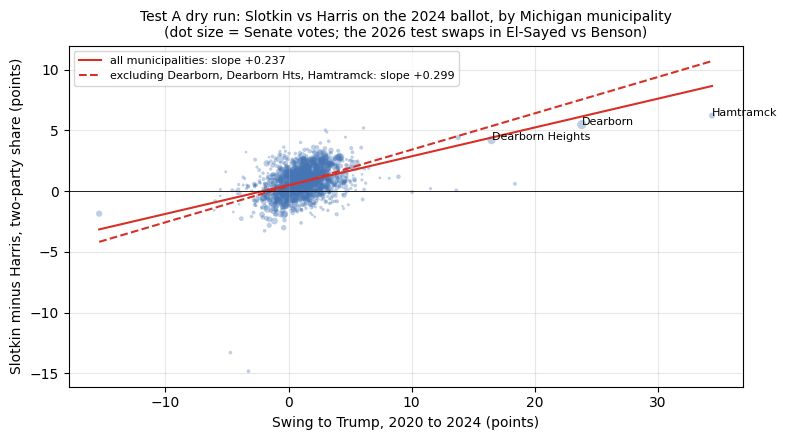

In [2]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(d.swing, d.gap, s=np.sqrt(d.sen_tot) / 4, alpha=0.35, color='#4575b4', edgecolor='none')
for _, r in d[arab].iterrows(): ax.annotate(r.muni.replace(' city', '').title(), (r.swing, r.gap), fontsize=8)
x = np.linspace(d.swing.min(), d.swing.max(), 50)
for lab, ls in [('all municipalities', '-'), ('excluding Dearborn, Dearborn Hts, Hamtramck', '--')]:
    ax.plot(x, res.loc[lab, 'intercept'] + res.loc[lab, 'slope'] * x, color='#d73027', ls=ls, lw=1.5, label=f'{lab}: slope {res.loc[lab, "slope"]:+.3f}')
ax.axhline(0, color='black', lw=0.6)
ax.set_xlabel('Swing to Trump, 2020 to 2024 (points)'); ax.set_ylabel('Slotkin minus Harris, two-party share (points)')
ax.set_title('Test A dry run: Slotkin vs Harris on the 2024 ballot, by Michigan municipality\n(dot size = Senate votes; the 2026 test swaps in El-Sayed vs Benson)', fontsize=10)
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.tight_layout()
plt.savefig('../outputs/figures/michigan_testA_dryrun_2024.png', dpi=150, bbox_inches='tight'); plt.show()

## 2022 benchmark: two mainstream Democrats, both down-ballot

The 2024 dry run pairs a Senate candidate with a presidential one; ticket-splitting between president and Senate produces a swing gradient on its own. In 2026 El-Sayed (Senate) and Benson (governor) are both down-ballot, with no presidential race. The closest precedent is Michigan 2022, when three mainstream Democrats won statewide on one ballot: Whitmer (governor), Nessel (attorney general), Benson (secretary of state). Same model: gap between two of them on the 2020→24 presidential swing, WLS weighted by governor votes, HC1, municipalities with ≥ 200 governor votes. The slopes show how much swing gradient ordinary candidate differences produce between down-ballot Democrats; a Test A slope inside that range would not distinguish El-Sayed's economics from ordinary candidate effects. Data: OpenElections 2022 precinct file, reconciled to certified totals within 0.05%; 1,517 municipalities matched, 99.8% of the vote.

In [3]:
k = pd.read_csv('../data/raw/michigan/mi_municipal_2020_2024_with_2022.csv')
k['gov_tot'] = k.gov_D_2022 + k.gov_R_2022
for o in ['gov', 'ag', 'sos']: k[f'{o}_sh'] = 100 * k[f'{o}_D_2022'] / (k[f'{o}_D_2022'] + k[f'{o}_R_2022'])
k['swing'] = 100 * (k.pres_R_2024 / (k.pres_D_2024 + k.pres_R_2024) - k.pres_R_2020 / (k.pres_D_2020 + k.pres_R_2020))
k = k[k.gov_tot >= 200].dropna(subset=['swing', 'gov_sh', 'ag_sh', 'sos_sh']).copy()
arab = k.muni.isin(['dearborn city', 'dearborn heights city', 'hamtramck city'])
rows = {}
for lab, a_, b_ in [('Nessel (AG) - Whitmer (Gov)', 'ag_sh', 'gov_sh'), ('Benson (SoS) - Whitmer (Gov)', 'sos_sh', 'gov_sh'), ('Nessel (AG) - Benson (SoS)', 'ag_sh', 'sos_sh')]:
    for sub, df in [('all', k), ('excl. Dearborn/Dearborn Hts/Hamtramck', k[~arab])]:
        df = df.assign(gap=df[a_] - df[b_])
        r = smf.wls('gap ~ swing', data=df, weights=df.gov_tot).fit(cov_type='HC1'); ci = r.conf_int().loc['swing']
        rows[(lab, sub)] = {'N': len(df), 'mean_gap': np.average(df.gap, weights=df.gov_tot), 'slope': r.params['swing'], 'se': r.bse['swing'], 'lo': ci[0], 'hi': ci[1], 'p': r.pvalues['swing']}
bench = pd.DataFrame(rows).T; print(bench.round(3).to_string())
bench.to_csv('../outputs/tables/michigan_testA_benchmark_2022.csv')

                                                                         N  mean_gap  slope     se     lo     hi      p
Nessel (AG) - Whitmer (Gov)  all                                    1436.0    -0.968 -0.023  0.010 -0.043 -0.003  0.025
                             excl. Dearborn/Dearborn Hts/Hamtramck  1433.0    -0.959 -0.002  0.022 -0.046  0.042  0.938
Benson (SoS) - Whitmer (Gov) all                                    1436.0     1.767  0.034  0.023 -0.011  0.079  0.139
                             excl. Dearborn/Dearborn Hts/Hamtramck  1433.0     1.757  0.035  0.056 -0.074  0.145  0.525
Nessel (AG) - Benson (SoS)   all                                    1436.0    -2.735 -0.057  0.029 -0.113 -0.001  0.046
                             excl. Dearborn/Dearborn Hts/Hamtramck  1433.0    -2.716 -0.037  0.070 -0.174  0.100  0.596
